## EDA dataset

In [1]:
# importing the libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.seasonal import seasonal_decompose


In [2]:
# importing the data
df = pd.read_csv('consumption_temp.csv')
df.head(10)

,time,location,consumption,temperature
0,2022-04-07 21:00:00,bergen,1.113325,-0.3
1,2022-04-07 21:00:00,oslo,4.092830,1.0
2,2022-04-07 21:00:00,stavanger,2.057858,1.3
3,2022-04-07 21:00:00,tromsø,1.246582,-3.9
4,2022-04-07 21:00:00,trondheim,1.970098,-2.8
5,2022-04-07 22:00:00,bergen,1.050327,0.0
6,2022-04-07 22:00:00,oslo,3.818095,0.4
7,2022-04-07 22:00:00,stavanger,1.918996,0.8
8,2022-04-07 22:00:00,tromsø,1.180321,-4.3
9,2022-04-07 22:00:00,trondheim,1.839443,-3.3


In [3]:
# setting the date as index
df = df.set_index(pd.to_datetime(df['time'])).drop(columns='time')

In [4]:
# checking for missing value
df.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 49494 entries, 2022-04-07 21:00:00 to 2023-04-02 21:00:00
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   location     49494 non-null  str    
 1   consumption  49494 non-null  float64
 2   temperature  49494 non-null  float64
dtypes: float64(2), str(1)
memory usage: 1.5 MB


In [5]:
df.describe()

,consumption,temperature
count,49494.000000,49494.000000
mean,3.509242,6.554019
std,3.096356,7.630308
min,0.000000,-17.299999
25%,1.263256,1.000000
50%,2.376530,6.800000
75%,5.189000,12.100000
max,18.045011,30.500000


In [6]:
# check whether any calendar days are missing
all_days = pd.date_range(
    start=df.index.min(),
    end=df.index.max(),
    freq="D"
)

missing_days = all_days.difference(df.index)

print(f"Number of missing days: {len(missing_days)}")
print("Missing dates:", missing_days)

Number of missing days: 0
Missing dates: DatetimeIndex([], dtype='datetime64[us]', freq='D')


In [7]:
# check whether any hours are missing
all_hours = pd.date_range(
    start=df.index.min(),
    end=df.index.max(),
    freq="h"
)

missing_hours = all_hours.difference(df.index)

print(f"Number of missing hours: {len(missing_hours)}")
print("Missing dates:", missing_hours)

Number of missing hours: 0
Missing dates: DatetimeIndex([], dtype='datetime64[us]', freq='h')


So there are no:
- NaN values
- Missing date/days
- Missing hours

In [8]:
df.shape

(49494, 3)

<Figure size 1000x400 with 0 Axes>

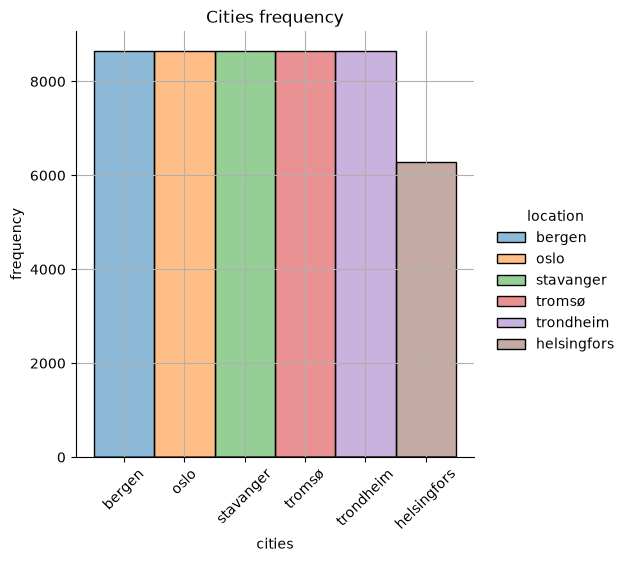

Max frequency 8641 | Min frequency 6289


In [9]:
# distributions
plt.figure(figsize=(10,4))
sns.displot(data=df, x='location', hue='location')
plt.ylabel('frequency')
plt.xlabel('cities')
plt.xticks(rotation=45)
plt.grid()
plt.title('Cities frequency')
plt.show()

print(f'Max frequency {df.location.value_counts().max()} | Min frequency {df.location.value_counts().min()}')


Now we anayze potential **outliers**.

=== GLOBAL OUTLIER SUMMARY ===


,Feature,IQR Lower,IQR Upper,IQR Outliers (N),IQR Outliers (%),Z-Score Outliers (N),Z-Score Outliers (%)
0,consumption,-4.63,11.08,2434,4.92,1283,2.59
1,temperature,-15.65,28.75,36,0.07,17,0.03



[Domain check] Records with consumption <= 0: 32 (0.06%)

=== OUTLIER SUMMARY GROUPED BY LOCATION (IQR METHOD) ===


,location,total_samples,consumption_outliers_n,consumption_outliers_pct,consumption_bounds,temperature_outliers_n,temperature_outliers_pct,temperature_bounds
0,bergen,8641,0,0.0,"[-2.4, 6.2]",39,0.45,"[-10.5, 25.8]"
1,helsingfors,6289,1151,18.3,"[5.8, 6.9]",0,0.00,"[-18.2, 29.5]"
2,oslo,8641,0,0.0,"[-10.7, 24.7]",0,0.00,"[-19.0, 34.1]"
3,stavanger,8641,0,0.0,"[-4.6, 11.4]",19,0.22,"[-8.3, 25.3]"
4,tromsø,8641,0,0.0,"[-0.7, 3.4]",24,0.28,"[-20.9, 27.9]"
5,trondheim,8641,0,0.0,"[-1.9, 6.5]",34,0.39,"[-14.7, 27.4]"


/var/folders/c2/bks64cl903qb0xc3xcdsslhm0000gn/T/ipykernel_36524/3226026017.py:82: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='location', y='consumption', ax=axes[0, 0], palette='Blues_r')
/var/folders/c2/bks64cl903qb0xc3xcdsslhm0000gn/T/ipykernel_36524/3226026017.py:88: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='location', y='temperature', ax=axes[0, 1], palette='coolwarm')


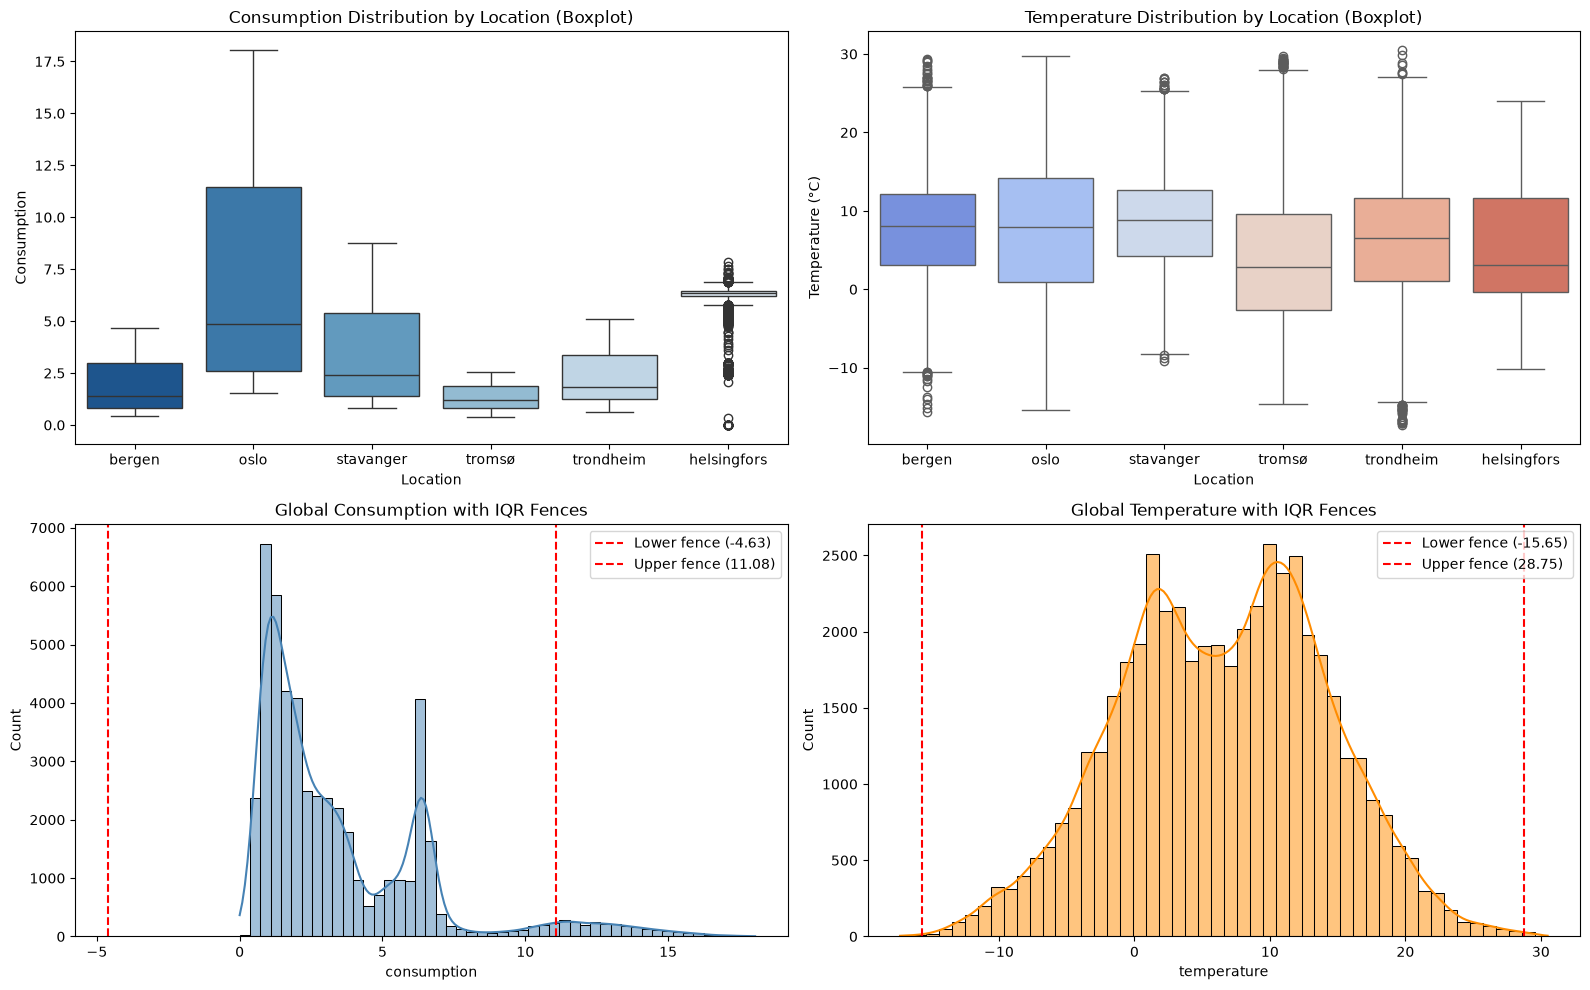

=== TOP 5 HIGHEST CONSUMPTION RECORDS ===


,location,consumption,temperature
time,,,
2022-12-24 15:00:00,oslo,18.045011,-11.0
2023-01-22 16:00:00,oslo,18.031449,-10.1
2023-01-22 17:00:00,oslo,18.025397,-10.1
2023-01-22 18:00:00,oslo,17.869247,-10.2
2023-01-03 16:00:00,oslo,17.865679,-12.1



=== TOP 6 EXTREME TEMPERATURE RECORDS (COLDEST & WARMEST) ===


,location,consumption,temperature
time,,,
2022-12-13 16:00:00,trondheim,4.786505,-17.299999
2022-12-13 11:00:00,trondheim,4.215958,-17.100000
2022-12-13 13:00:00,trondheim,4.280036,-17.000000
2022-06-25 12:00:00,trondheim,0.860169,30.500000
2022-06-25 11:00:00,trondheim,0.851429,29.900000
2022-06-25 13:00:00,oslo,2.318009,29.799999


In [10]:
# ==============================================================================
# OUTLIER DETECTION ANALYSIS (GLOBAL & PER-LOCATION)
# ==============================================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

target_cols = ['consumption', 'temperature']

# ------------------------------------------------------------------------------
# 1. IQR & Z-SCORE FUNCTIONS
# ------------------------------------------------------------------------------
def detect_iqr_outliers(series, factor=1.5):
    """Detect outliers using the Interquartile Range (IQR) rule."""
    q25 = series.quantile(0.25)
    q75 = series.quantile(0.75)
    iqr = q75 - q25
    lower_bound = q25 - factor * iqr
    upper_bound = q75 + factor * iqr
    is_outlier = (series < lower_bound) | (series > upper_bound)
    return is_outlier, lower_bound, upper_bound

def detect_zscore_outliers(series, threshold=3.0):
    """Detect outliers using standard Z-score (|z| > threshold)."""
    std = series.std()
    if std == 0 or np.isnan(std):
        return pd.Series(False, index=series.index)
    z_scores = (series - series.mean()) / std
    return z_scores.abs() > threshold

# ------------------------------------------------------------------------------
# 2. GLOBAL OUTLIER SUMMARY
# ------------------------------------------------------------------------------
print("=== GLOBAL OUTLIER SUMMARY ===")
global_summary = []
for col in target_cols:
    iqr_mask, lower, upper = detect_iqr_outliers(df[col])
    z_mask = detect_zscore_outliers(df[col])
    global_summary.append({
        'Feature': col,
        'IQR Lower': round(lower, 2),
        'IQR Upper': round(upper, 2),
        'IQR Outliers (N)': iqr_mask.sum(),
        'IQR Outliers (%)': round(iqr_mask.mean() * 100, 2),
        'Z-Score Outliers (N)': z_mask.sum(),
        'Z-Score Outliers (%)': round(z_mask.mean() * 100, 2),
    })

global_summary_df = pd.DataFrame(global_summary)
display(global_summary_df)

# Check for domain-specific invalid values (e.g., non-positive consumption)
zero_consumption = (df['consumption'] <= 0).sum()
print(f"\n[Domain check] Records with consumption <= 0: {zero_consumption} ({zero_consumption / len(df) * 100:.2f}%)")

# ------------------------------------------------------------------------------
# 3. GROUPED OUTLIER DETECTION (BY LOCATION)
# ------------------------------------------------------------------------------
# Consumption scales and temperatures differ across cities, so location-wise detection is crucial.
print("\n=== OUTLIER SUMMARY GROUPED BY LOCATION (IQR METHOD) ===")
location_outlier_records = []

for loc, group in df.groupby('location'):
    row = {'location': loc, 'total_samples': len(group)}
    for col in target_cols:
        iqr_mask, lower, upper = detect_iqr_outliers(group[col])
        row[f'{col}_outliers_n'] = iqr_mask.sum()
        row[f'{col}_outliers_pct'] = round(iqr_mask.mean() * 100, 2)
        row[f'{col}_bounds'] = f"[{lower:.1f}, {upper:.1f}]"
    location_outlier_records.append(row)

loc_summary_df = pd.DataFrame(location_outlier_records)
display(loc_summary_df)

# ------------------------------------------------------------------------------
# 4. VISUAL DIAGNOSTICS: BOXPLOTS AND DISTRIBUTIONS
# ------------------------------------------------------------------------------
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# Boxplot of consumption by location
sns.boxplot(data=df, x='location', y='consumption', ax=axes[0, 0], palette='Blues_r')
axes[0, 0].set_title('Consumption Distribution by Location (Boxplot)')
axes[0, 0].set_xlabel('Location')
axes[0, 0].set_ylabel('Consumption')

# Boxplot of temperature by location
sns.boxplot(data=df, x='location', y='temperature', ax=axes[0, 1], palette='coolwarm')
axes[0, 1].set_title('Temperature Distribution by Location (Boxplot)')
axes[0, 1].set_xlabel('Location')
axes[0, 1].set_ylabel('Temperature (°C)')

# Overall histogram with IQR fences for consumption
sns.histplot(df['consumption'], kde=True, ax=axes[1, 0], color='steelblue', bins=50)
_, c_low, c_up = detect_iqr_outliers(df['consumption'])
axes[1, 0].axvline(c_low, color='red', linestyle='--', label=f'Lower fence ({c_low:.2f})')
axes[1, 0].axvline(c_up, color='red', linestyle='--', label=f'Upper fence ({c_up:.2f})')
axes[1, 0].set_title('Global Consumption with IQR Fences')
axes[1, 0].legend()

# Overall histogram with IQR fences for temperature
sns.histplot(df['temperature'], kde=True, ax=axes[1, 1], color='darkorange', bins=50)
_, t_low, t_up = detect_iqr_outliers(df['temperature'])
axes[1, 1].axvline(t_low, color='red', linestyle='--', label=f'Lower fence ({t_low:.2f})')
axes[1, 1].axvline(t_up, color='red', linestyle='--', label=f'Upper fence ({t_up:.2f})')
axes[1, 1].set_title('Global Temperature with IQR Fences')
axes[1, 1].legend()

plt.tight_layout()
plt.show()

# ------------------------------------------------------------------------------
# 5. SAMPLE INSPECTION: TOP EXTREME OUTLIERS
# ------------------------------------------------------------------------------
print("=== TOP 5 HIGHEST CONSUMPTION RECORDS ===")
display(df.nlargest(5, 'consumption'))

print("\n=== TOP 6 EXTREME TEMPERATURE RECORDS (COLDEST & WARMEST) ===")
display(pd.concat([df.nsmallest(3, 'temperature'), df.nlargest(3, 'temperature')]))

### Outlier Analysis & Data Quality Assessment

Based on the statistical detection (IQR and Z-score) and domain-specific checks, we conclude that **no natural consumption or temperature extremes should be trimmed or removed**, with the exception of an initial sensor startup artifact in **Helsingfors**:

1. **Oslo High Consumption (~18 MW)**:
   - While flagged as a statistical outlier globally (~4.9% of total rows), per-location IQR analysis reveals **0.0% outliers for Oslo**. 
   - The highest peaks occur on **Christmas Eve (2022-12-24 15:00)** and during freezing January days (**-10 °C to -12 °C**). In Norway, space heating is predominantly electric; these peaks reflect genuine, physics-driven surges in residential and commercial demand. Removing them would artificially truncate peak-load risk and distort imbalance cost evaluations.

2. **Extreme Temperatures (-17.3 °C to +30.5 °C)**:
   - The extreme minimum of **-17.3 °C** occurred in Trondheim during a severe cold front on December 13, 2022.
   - The maximum of **+30.5 °C** occurred during the documented Scandinavian heatwave of late June 2022 (June 25, 2022).
   - Both are physically valid, verified meteorological records. Retaining them is essential for models to learn weather-elastic demand sensitivity.

3. **Helsingfors Narrow IQR Variance**:
   - The 18.3% of points flagged as outliers in Helsingfors is a statistical artifact caused by an exceptionally narrow interquartile range ($\text{IQR} = 0.28\text{ MW}$ around a baseline of $\sim 6.35\text{ MW}$). The points outside the bounds represent normal seasonal heating/cooling cycles rather than data corruption.

4. **Actionable Anomaly — The 32 Initial Zeros in Helsingfors**:
   - Exactly 32 consecutive observations in `helsingfors` report `consumption == 0.0 MW`, running continuously from `2022-07-14 21:00:00` to `2022-07-16 04:00:00`.
   - This corresponds precisely to the very start of the Helsingfors recording series, indicating a meter initialization/telemetry latency before active data streaming began.
   - **Remediation**: Rather than dropping random rows (which would introduce time-series gaps and break autoregressive lag structures), we trim the start date for Helsingfors to **2022-07-16 05:00:00**, ensuring complete hourly continuity (`freq='h'`) across all locations.

In [11]:
# ==============================================================================
# REMEDIATION: TRIM UNMETERED INITIAL STARTUP FOR HELSINGFORS
# ==============================================================================
# The first 32 hours of Helsingfors (2022-07-14 21:00 to 2022-07-16 04:00) 
# contain 0.0 MW artifacts from sensor commissioning. We trim the series to begin
# at 2022-07-16 05:00:00, preserving complete hourly continuity.

initial_len = len(df)

# Filter out the initial 32 unmetered hours of Helsingfors
helsinki_startup_mask = (df['location'] == 'helsingfors') & (df.index < '2022-07-16 05:00:00')
df = df[~helsinki_startup_mask]

# Verification checks
removed_count = initial_len - len(df)
remaining_zeros = (df['consumption'] <= 0).sum()

h_series = df[df['location'] == 'helsingfors']
expected_h_range = pd.date_range(start=h_series.index.min(), end=h_series.index.max(), freq='h')
missing_h_hours = len(expected_h_range.difference(h_series.index))

print(f"Rows removed: {removed_count} (expected: 32)")
print(f"Remaining records with consumption <= 0: {remaining_zeros}")
print(f"New Helsingfors start date: {h_series.index.min()}")
print(f"Missing hourly timestamps in Helsingfors: {missing_h_hours}")
print(f"Updated DataFrame shape: {df.shape}")

Rows removed: 32 (expected: 32)
Remaining records with consumption <= 0: 0
New Helsingfors start date: 2022-07-16 05:00:00
Missing hourly timestamps in Helsingfors: 0
Updated DataFrame shape: (49462, 3)


Now let's analyze the **Consumption:** average hourly electricity consumption served by the retailer, measured in MW.

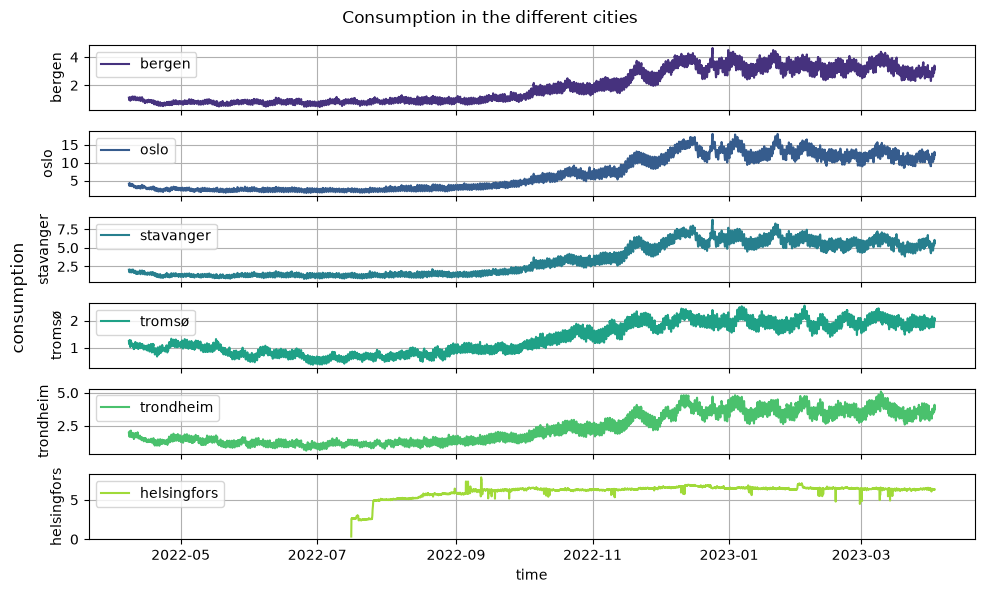

In [12]:
# analysing the consumption in the different cities timeseries
cities = df['location'].unique()
palette = sns.color_palette('viridis', len(cities))

fig, ax = plt.subplots(6, 1, figsize=(10, 6), sharex=True)

for i, city in enumerate(cities):
    sns.lineplot(
        df[df['location'] == city], 
        x='time', 
        y='consumption', 
        ax=ax[i], 
        label=city, 
        color=palette[i] 
    )
    ax[i].grid()
    ax[i].set_ylabel(f'{city}')

plt.xlabel('time')
fig.supylabel('consumption')
fig.suptitle('Consumption in the different cities') 
plt.tight_layout()
plt.show()

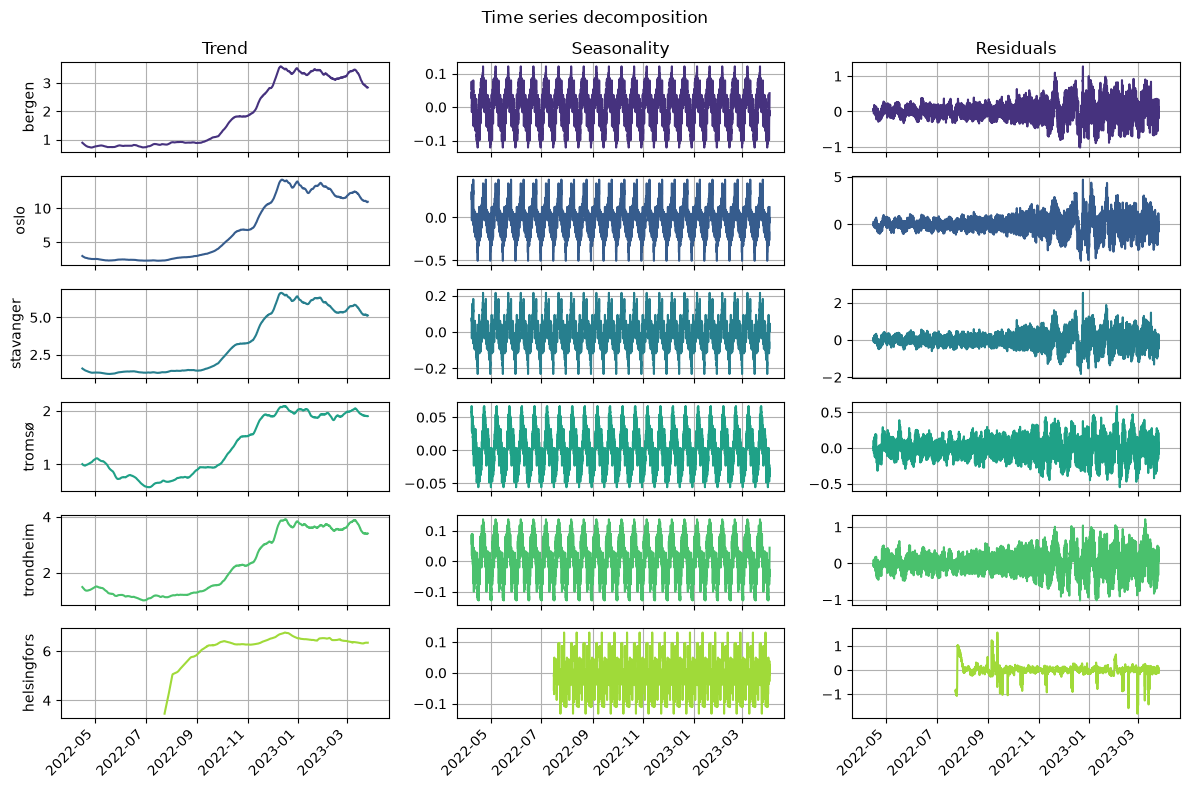

In [13]:
# Consumption time sereis decomposiont (for each city)

# get the city name
cities = df['location'].unique()

# color palette
palette = sns.color_palette('viridis', len(cities))

# creating a grid 6x3
#   6: cities
#   3: components
fig, ax = plt.subplots(6,3, figsize=(12, 8), sharex=True)

for i, city in enumerate(cities):
    
    # get city data
    df_city = df[df['location'] == city].copy()
    
    # time series decomposiotion
    decomposition = seasonal_decompose(df_city['consumption'], model='additive', period=365)
    trend = decomposition.trend
    seasonal = decomposition.seasonal
    resid = decomposition.resid
    
    # getting city color from the palette
    color = palette[i]
    
    # plot of the 3 components
    #   trend
    ax[i, 0].plot(trend.index, trend, color=color)
    ax[i, 0].set_ylabel(f'{city}')
    ax[i, 0].grid()
    # sesonality
    ax[i, 1].plot(seasonal.index, seasonal, color=color)
    ax[i, 1].grid()
    # residuals
    ax[i, 2].plot(resid.index, resid, color=color)
    ax[i, 2].grid()

# titles
ax[0, 0].set_title('Trend')
ax[0, 1].set_title('Seasonality')
ax[0, 2].set_title('Residuals')

fig.autofmt_xdate(rotation=45, ha='right')

fig.suptitle('Time series decomposition')
plt.tight_layout()
plt.show()

### Consumption VS Tempearature

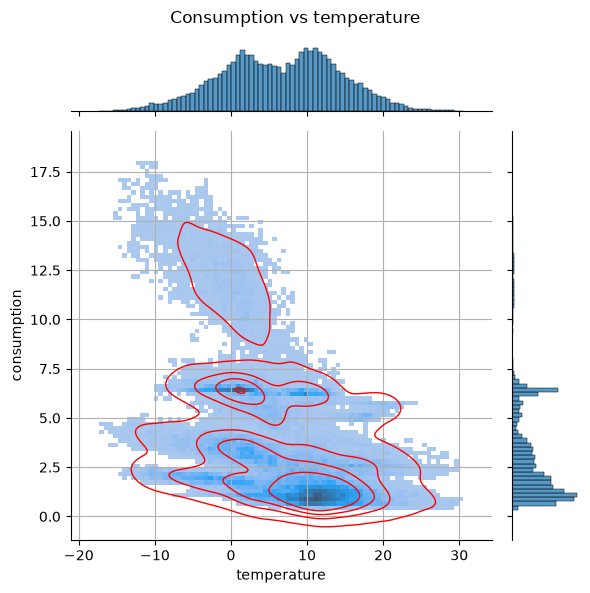

In [14]:
sns.jointplot(data=df, x='temperature', y='consumption', kind='hist')
sns.kdeplot(data=df, x='temperature', y='consumption', levels=5, color="red", linewidths=1)
plt.suptitle('Consumption vs temperature')
plt.grid()
plt.tight_layout()
plt.show()

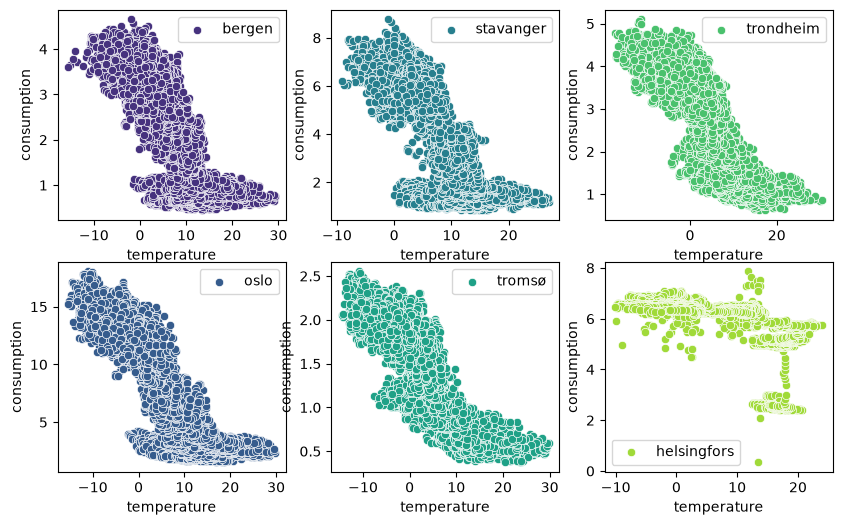

In [15]:
# get the city name
cities = df['location'].unique()
# color palette
palette = sns.color_palette('viridis', len(cities))
# plotting
fig, ax = plt.subplots(2,3, figsize=(10,6))
count = 0
j = 0
i = 0
for a, city in enumerate(cities):
    sns.scatterplot(data=df[df['location']==city], x='temperature',
                        y='consumption', color=palette[a], ax=ax[i,j],
                        label=city)
    count += 1
    i += 1
    if count == 2 and i == 2:
        j += 1
        count = 0
        i = 0


In [16]:
# enconding the cities names
df['location'] = df['location'].astype('category')
corr_mat = df.groupby('location', observed=True)[['consumption', 'temperature']].corr().xs('temperature', level=1)['consumption']
corr_mat

location
bergen        -0.781353
helsingfors   -0.600614
oslo          -0.861854
stavanger     -0.781747
tromsø        -0.863436
trondheim     -0.837779
Name: consumption, dtype: float64

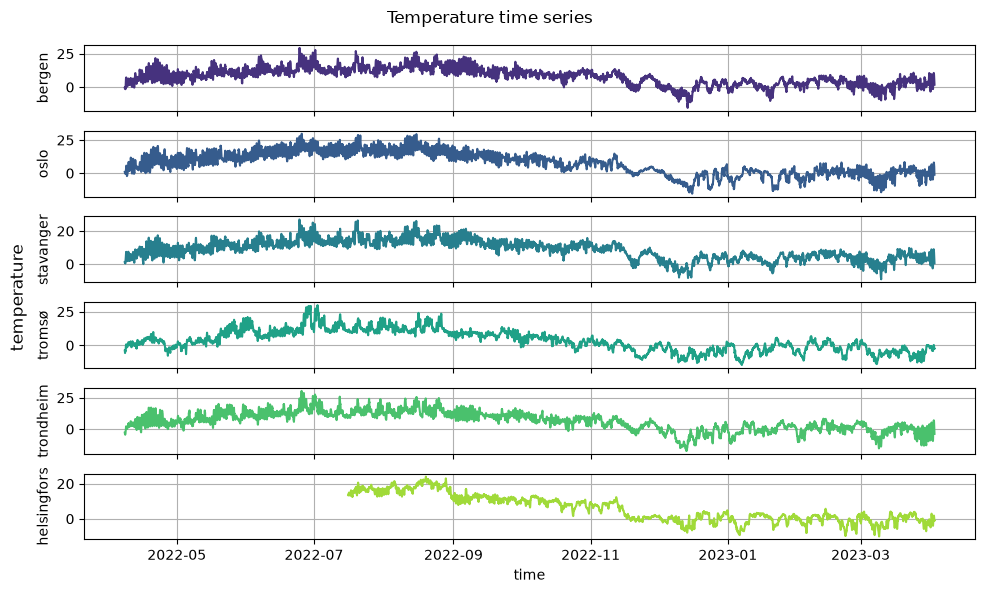

In [17]:
fig, ax = plt.subplots(6,1, figsize=(10,6), sharex=True)
cities = df['location'].unique()
palette = sns.color_palette('viridis', len(cities))
for i, city in enumerate(cities):
    sns.lineplot(data=df[df['location']==city], x='time', y='temperature', color=palette[i], ax=ax[i])
    ax[i].grid()
    ax[i].set_ylabel(f'{city}')

fig.supylabel('temperature')
fig.suptitle('Temperature time series')
plt.tight_layout()
plt.show()

### Model proposal

1. Baseline: same hour at D-7.
2. LightGBM global on normalized target:
    - features: houre, week day, weekends, weather forecast, hourly lags 120/144/168/336h, rolling average at lag ≥ 120h. 
        - Avoid month; 
        - Location as category (no LabelEncoder).
3. Ridge/GAM for area.


### Features

In [20]:
# need to have time local time for each area
df.index = df.index.tz_localize('UTC')   
tz = {'helsingfors': 'Europe/Helsinki'}  

parts = []
for loc, g in df.groupby('location'):
    t = g.index.tz_convert(tz.get(loc, 'Europe/Oslo'))
    parts.append(g.assign(hour=t.hour, dow=t.dayofweek, local_date=t.normalize().tz_localize(None)))
df = pd.concat(parts).sort_index()

In [21]:
import holidays

cal = {'helsingfors': holidays.Finland(years=[2022, 2023])}
default_cal = holidays.Norway(years=[2022, 2023])

df['is_holiday'] = [
    d in cal.get(loc, default_cal)
    for d, loc in zip(df['local_date'], df['location'])
]

# is_off = holidays or weekends
df['is_off'] = (df['is_holiday'] | (df['dow'] >= 5)).astype(int)
df['day_of_week'] = df['dow']
df= df.drop(columns='dow')

In [22]:
df.head(10)

,location,consumption,temperature,baseline_pred_7d,hour,local_date,is_holiday,is_off,day_of_week
time,,,,,,,,,
2022-04-07 21:00:00+00:00,bergen,1.113325,-0.3,NaN,23,2022-04-07,False,0,3
2022-04-07 21:00:00+00:00,stavanger,2.057858,1.3,NaN,23,2022-04-07,False,0,3
2022-04-07 21:00:00+00:00,tromsø,1.246582,-3.9,NaN,23,2022-04-07,False,0,3
2022-04-07 21:00:00+00:00,trondheim,1.970098,-2.8,NaN,23,2022-04-07,False,0,3
2022-04-07 21:00:00+00:00,oslo,4.092830,1.0,NaN,23,2022-04-07,False,0,3
2022-04-07 22:00:00+00:00,oslo,3.818095,0.4,NaN,0,2022-04-08,False,0,4
2022-04-07 22:00:00+00:00,bergen,1.050327,0.0,NaN,0,2022-04-08,False,0,4
2022-04-07 22:00:00+00:00,stavanger,1.918996,0.8,NaN,0,2022-04-08,False,0,4
2022-04-07 22:00:00+00:00,tromsø,1.180321,-4.3,NaN,0,2022-04-08,False,0,4


In [23]:
df.loc[df['is_holiday'], 'local_date'].drop_duplicates().sort_values().dt.date.tolist()

[datetime.date(2022, 4, 14),
 datetime.date(2022, 4, 15),
 datetime.date(2022, 4, 17),
 datetime.date(2022, 4, 18),
 datetime.date(2022, 5, 1),
 datetime.date(2022, 5, 17),
 datetime.date(2022, 5, 26),
 datetime.date(2022, 6, 5),
 datetime.date(2022, 6, 6),
 datetime.date(2022, 11, 5),
 datetime.date(2022, 12, 6),
 datetime.date(2022, 12, 24),
 datetime.date(2022, 12, 25),
 datetime.date(2022, 12, 26),
 datetime.date(2023, 1, 1),
 datetime.date(2023, 1, 6)]

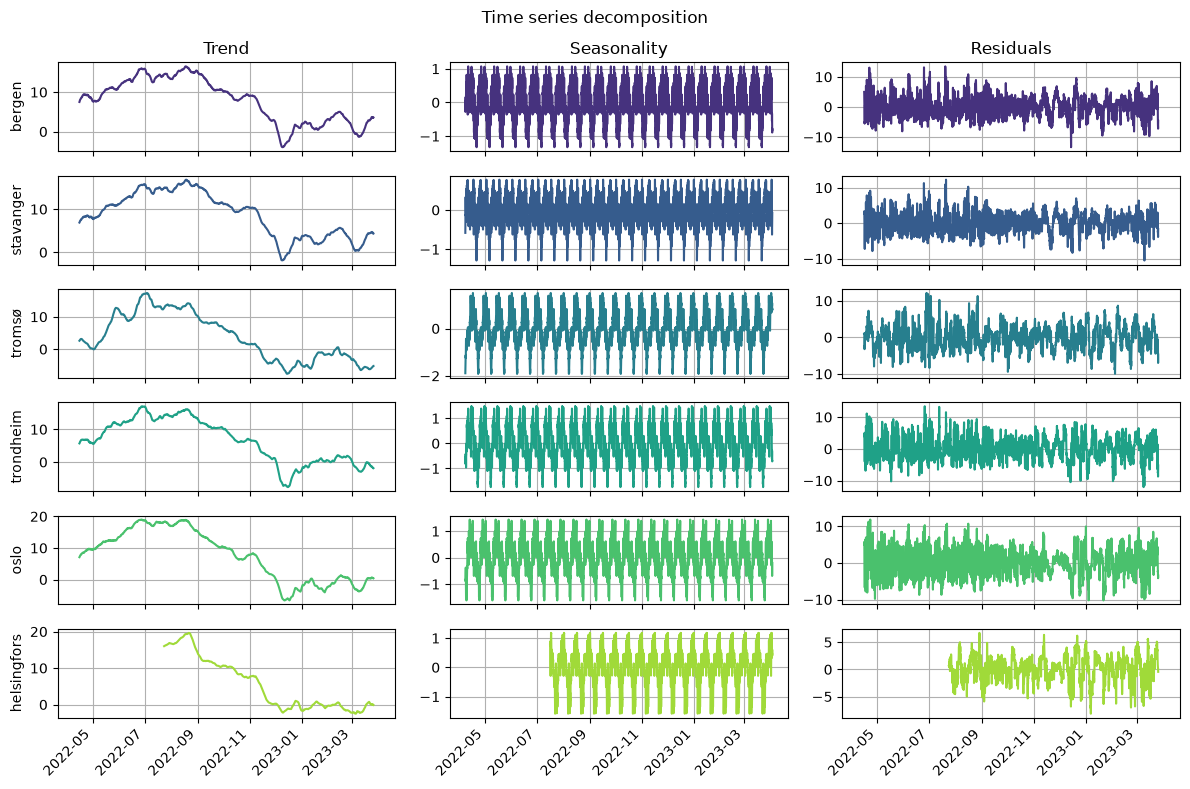

In [24]:
# Consumption time sereis decomposiont (for each city)

# get the city name
cities = df['location'].unique()

# color palette
palette = sns.color_palette('viridis', len(cities))

# creating a grid 6x3
#   6: cities
#   3: components
fig, ax = plt.subplots(6,3, figsize=(12, 8), sharex=True)

for i, city in enumerate(cities):
    
    # get city data
    df_city = df[df['location'] == city].copy()
    
    # time series decomposiotion
    decomposition = seasonal_decompose(df_city['temperature'], model='additive', period=365)
    trend = decomposition.trend
    seasonal = decomposition.seasonal
    resid = decomposition.resid
    
    # getting city color from the palette
    color = palette[i]
    
    # plot of the 3 components
    #   trend
    ax[i, 0].plot(trend.index, trend, color=color)
    ax[i, 0].set_ylabel(f'{city}')
    ax[i, 0].grid()
    # sesonality
    ax[i, 1].plot(seasonal.index, seasonal, color=color)
    ax[i, 1].grid()
    # residuals
    ax[i, 2].plot(resid.index, resid, color=color)
    ax[i, 2].grid()

# titles
ax[0, 0].set_title('Trend')
ax[0, 1].set_title('Seasonality')
ax[0, 2].set_title('Residuals')

fig.autofmt_xdate(rotation=45, ha='right')

fig.suptitle('Time series decomposition')
plt.tight_layout()
plt.show()

In [25]:
df.is_off.value_counts()

is_off
0    34254
1    15208
Name: count, dtype: int64

### Consumption by city: week days vs of days

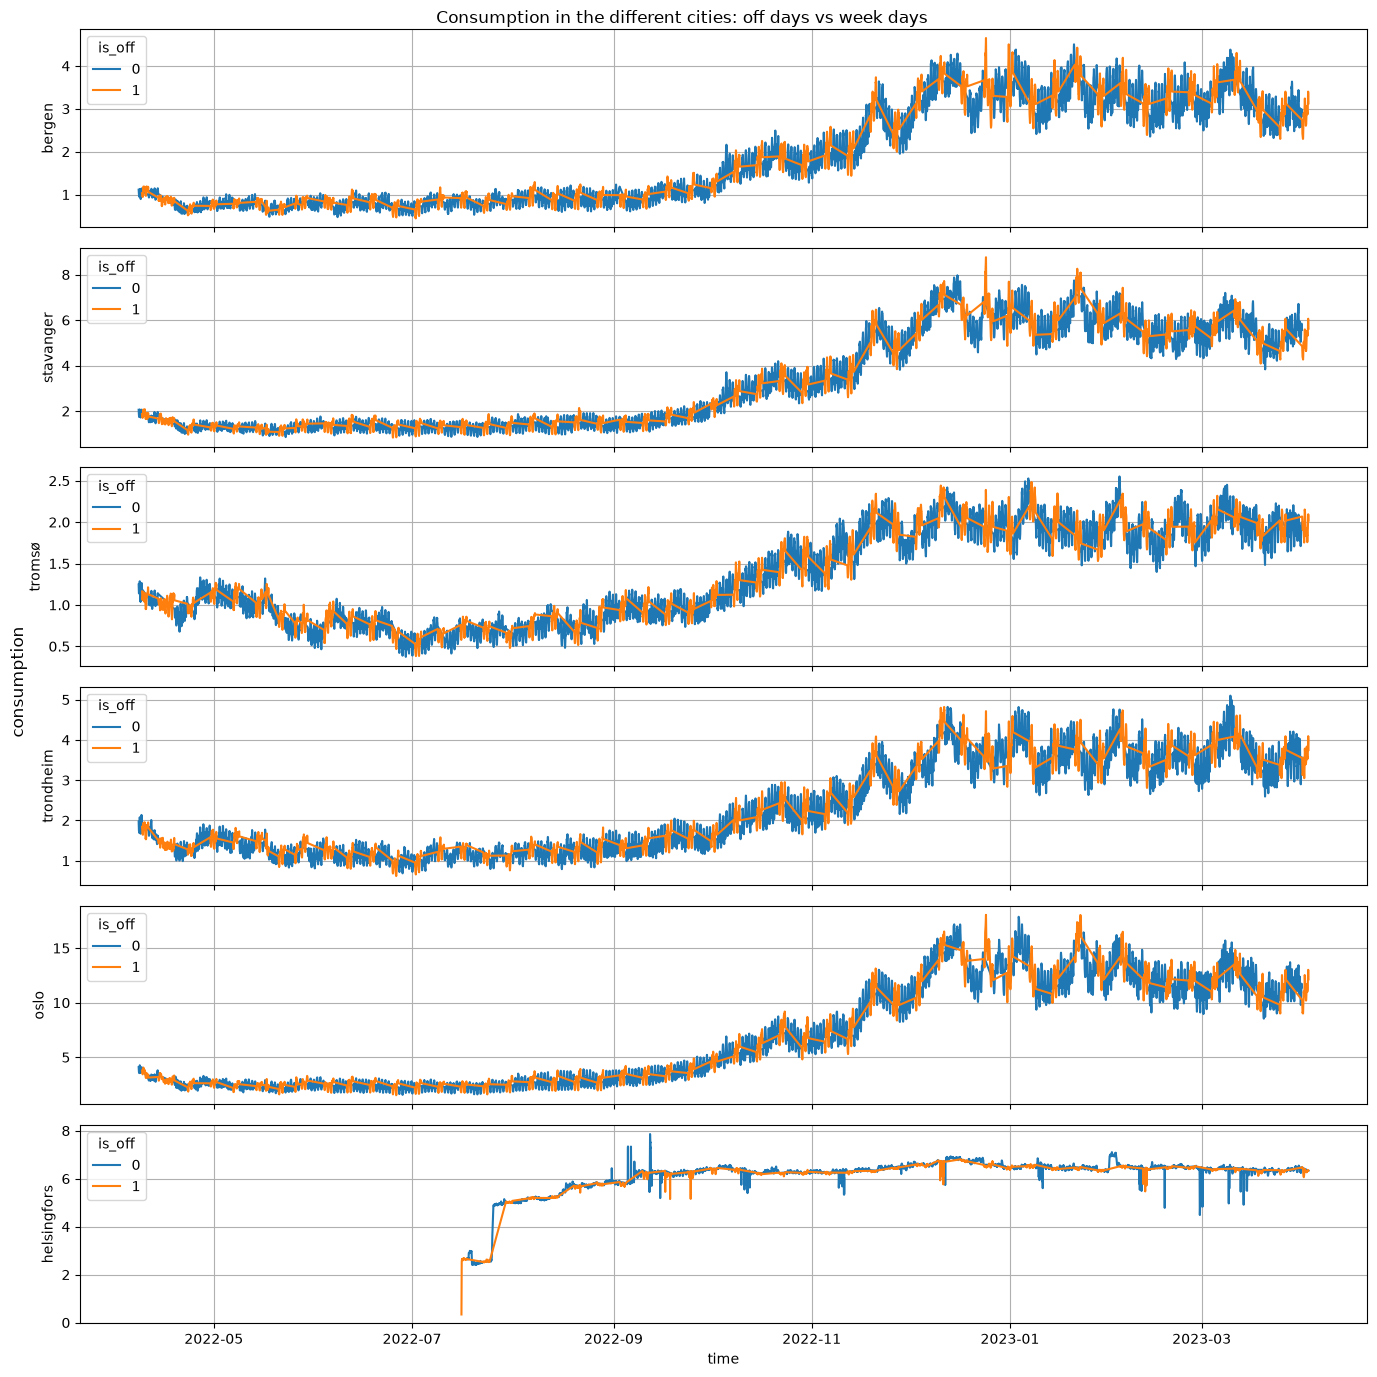

In [26]:
# analysing the consumption in the different cities timeseries
cities = df['location'].unique()
palette = sns.color_palette('viridis', len(cities))

fig, ax = plt.subplots(6, 1, figsize=(14,14), sharex=True)


for i, city in enumerate(cities):
    city_maks = df['location'] == city
    sns.lineplot(
        df[city_maks], 
        x='time', 
        y='consumption', 
        ax=ax[i], 
        hue='is_off',
        color=palette[i] 
    )
    ax[i].grid()
    ax[i].set_ylabel(f'{city}')

plt.xlabel('time')
fig.supylabel('consumption')
fig.suptitle('Consumption in the different cities: off days vs week days') 
plt.tight_layout()
plt.show()

**Consumption trend in the different cities: off days vs week days**

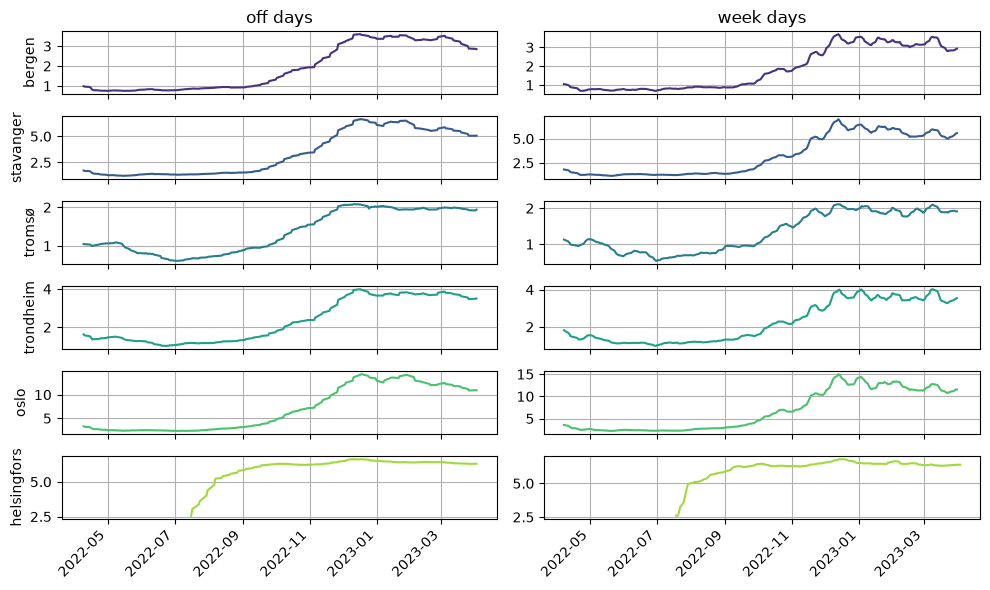

In [27]:
fig, ax = plt.subplots(6, 2, figsize=(10, 6), sharex=True)

for i, city in enumerate(cities):
    d = df[df['location'] == city]
    for j, off in enumerate([1, 0]):
        s = d[d['is_off'] == off].groupby('local_date')['consumption'].mean()
        ax[i, j].plot(s.rolling(7, center=True, min_periods=1).mean(), color=palette[i])
        ax[i, j].grid()
    ax[i, 0].set_ylabel(city)

ax[0, 0].set_title('off days'); ax[0, 1].set_title('week days')
fig.autofmt_xdate(rotation=45, ha='right')
plt.tight_layout(); plt.show()

### Consumption trend vs temperature trend

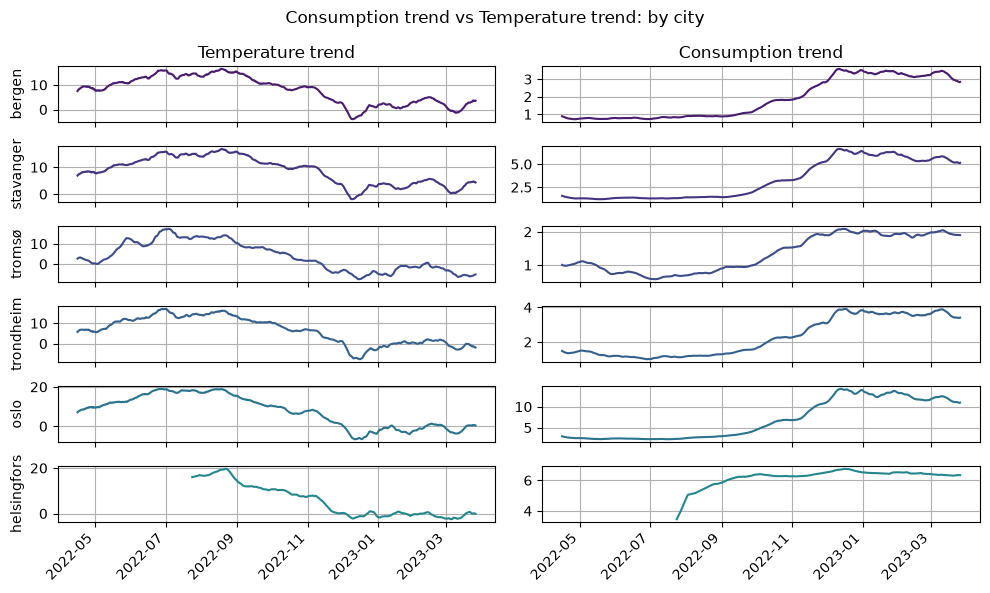

In [28]:
# for each city
cities = df['location'].unique()
palette = sns.color_palette('viridis', len(cities) * 2)

# plot
fig, ax = plt.subplots(6,2, figsize=(10,6), sharex=True)
for i, city in enumerate(cities):
    
    # get city data
    df_city = df[df['location'] == city].copy()
    
    # time series decomposiotion
    decomposition_temp = seasonal_decompose(df_city['temperature'], model='additive', period=365)
    decomposition_cons = seasonal_decompose(df_city['consumption'], model='additive', period=365)
    trend_temp = decomposition_temp.trend
    trend_cons = decomposition_cons.trend
    
    # plot of the 3 components
    #   trend_temp
    ax[i, 0].plot(trend_temp.index, trend_temp, color=palette[i])
    ax[i, 0].set_ylabel(f'{city}')
    ax[i, 0].grid()
    # trend_cons
    ax[i, 1].plot(trend_cons.index, trend_cons, color=palette[i])
    ax[i, 1].grid()



fig.autofmt_xdate(rotation=45, ha='right')
ax[0,0].set_title('Temperature trend')
ax[0,1].set_title('Consumption trend')

fig.suptitle('Consumption trend vs Temperature trend: by city')
plt.tight_layout()
plt.show()